# EV Charging Demand Classification

## Project objective
The goal of classification is to predict whether an EV charging session belongs to:

- **Normal Demand = 0**
- **High Demand = 1**

## 1. Load and inspect the dataset

### What this code does
- `pd.read_csv(...)` loads the prepared EV charging dataset into a pandas DataFrame called `df`.
- `df.columns` shows all available columns.
- `df.shape` shows the number of rows and columns.

### Output
The dataset contains **72,241 rows and 18 columns**.

In [77]:
import pandas as pd

# 1. Load the dataset
df = pd.read_csv('data/ev_charging_featured_model.csv')

# 2. Display column names
print("---Column names---")
print(df.columns)

# 3. Display dataset size
print("\n---Dataset size---")
print(df.shape)

---Column names---
Index(['chargercompany', 'location', 'chargertype', 'duration', 'demand',
       'start_full', 'start_hour', 'day_of_week_number', 'log_duration',
       'start_year', 'start_month', 'start_day', 'start_minute',
       'week_of_year', 'is_weekend', 'time_of_day', 'user_previous_sessions',
       'charger_previous_sessions', 'location_previous_sessions'],
      dtype='object')

---Dataset size---
(72241, 19)


## 2. Create the classification target

The original `demand` column is numeric. A classification model needs categories, so this code converts demand into two classes.

### Step-by-step
1. The median demand is calculated.
2. The median is **14.25**.
3. If `demand >= 14.25`, the row is labeled **High Demand**.
4. If `demand < 14.25`, the row is labeled **Normal Demand**.
5. The text labels are mapped to numbers:
   - **Normal Demand → 0**
   - **High Demand → 1**

### Why use the median?
The median creates a simple split around the middle of the demand values. In this dataset it also produces almost equal class sizes.

### point
The numeric `demand` column is used to **create the target**, but it is **not included later as an input feature**. This avoids directly giving the answer to the model.

In [78]:
import numpy as np

# Calculate the median demand
median_demand = df['demand'].median()

print("Median Demand:", median_demand)

# Create the demand category target
df['demand_category'] = np.where(
    df['demand'] >= median_demand,
    'High Demand',
    'Normal Demand'
)

# Convert text labels into numeric labels for classification
df['target'] = df['demand_category'].map({
    'Normal Demand': 0,
    'High Demand': 1
})

# Check the number of rows in each class
print(df['demand_category'].value_counts())

Median Demand: 14.25
demand_category
High Demand      36143
Normal Demand    36098
Name: count, dtype: int64


## 3. Check class balance

`value_counts(normalize=True) * 100` converts class counts into percentages.

### Result
- **High Demand: 50.03%**
- **Normal Demand: 49.97%**

The classes are nearly equally distributed (50.03% High Demand and 49.97% Normal Demand), so class imbalance is not a concern for this dataset.

Since the target classes were already balanced, Random Oversampling, SMOTE, and ADASYN were not applied.

In [79]:
df['demand_category'].value_counts(normalize=True) * 100

demand_category
High Demand      50.031146
Normal Demand    49.968854
Name: proportion, dtype: float64

## 4. Select features and create a chronological train-test split

### Feature groups

**Numeric features** contain numbers such as:
- duration
- start month/day/hour/minute
- day of week
- week of year
- weekend indicator
- previous session counts

**Categorical features** contain labels such as:
- location
- time of day
- charger type
- charger company

`x` contains the model input features and `y` contains the target.

### chronological split
The first 80% of rows are used for training and the last 20% are used for testing.

There is **no shuffling**. This is useful when the row order represents time because the model learns from earlier observations and is tested on later observations.

### Split balance
The training and testing sets both remain close to 50-50 between the two classes.

In [80]:
# 1. Define numeric and categorical feature groups
numeric_features = [
    'duration',
    'start_month',
    'start_day',
    'start_hour',
    'start_minute',
    'day_of_week_number',
    'week_of_year',
    'is_weekend'
]

 #'user_previous_sessions',
    #'charger_previous_sessions',
    #'location_previous_sessions'
categorical_features = [
    'location',
    'time_of_day',
    'chargertype',
    'chargercompany',
]

x = df[numeric_features + categorical_features]
y = df['target']

# 2. Chronological 80/20 train-test split (no shuffling)
split_idx = int(len(df) * 0.80)

x_train = x.iloc[:split_idx]
x_test = x.iloc[split_idx:]
y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

# 3. Check class distribution in the training and testing sets
print("\n--- Training Set Class Balance ---")
print(y_train.value_counts(normalize=True) * 100)

print("\n--- Testing Set Class Balance ---")
print(y_test.value_counts(normalize=True) * 100)



--- Training Set Class Balance ---
target
1    50.299349
0    49.700651
Name: proportion, dtype: float64

--- Testing Set Class Balance ---
target
0    51.041595
1    48.958405
Name: proportion, dtype: float64


## 5. Preprocessing

Different feature types need different preparation before they are passed to the models.

### Numeric features — `StandardScaler`
`StandardScaler()` places numeric features on a comparable scale.

### Categorical features — `OneHotEncoder`
`OneHotEncoder()` converts text categories into numeric indicator columns.

- `drop='first'` removes one reference category from each categorical feature.
- `handle_unknown='ignore'` prevents an error if a category appears in test data that was not seen during training.

### ColumnTransformer
It allows different preprocessing steps to be applied to numeric and categorical columns in one object.

### Pipeline
Each model later combines this preprocessor with the classifier. This keeps preprocessing and modeling together and helps ensure the same transformations are applied consistently.

In [81]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

# 1. Create the preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        (
            'cat',
            OneHotEncoder(drop='first', handle_unknown='ignore'),
            categorical_features,
        ),
    ]
)


## 6. Evaluation metrics used for every model

### Inputs
- `y_test` = actual class labels
- `y_pred` = predicted class labels
- `y_proba` = predicted probability/score for **High Demand (class 1)**

### Accuracy
**Question:** Out of all test rows, how many were classified correctly?

Higher is better, but accuracy should not be considered alone.

### Precision
**Question:** Out of all rows predicted as **High Demand**, how many were actually High Demand?

High precision means fewer **false high-demand alerts**.

### Recall
**Question:** Out of all actual **High Demand** rows, how many did the model successfully find?

High recall means fewer real high-demand cases are missed.

### F1 Score
F1 combines **Precision and Recall** into one balanced score.

It is useful when both false positives and false negatives matter.

### ROC-AUC
ROC-AUC measures how well the model separates High Demand from Normal Demand across different classification thresholds.

- Around **0.5** = weak/random separation
- Closer to **1.0** = stronger separation

### Simple memory trick
- **Accuracy:** overall correct
- **Precision:** when model says High, how often is it right?
- **Recall:** from all real High cases, how many did it catch?
- **F1:** balance of Precision and Recall
- **ROC-AUC:** overall ability to separate the two classes

In [82]:
def evaluate_model(model_name, y_test, y_pred, y_proba):
    print(f"\n=== {model_name} ===")

    print(
        "Accuracy :",
        round(accuracy_score(y_test, y_pred), 4)
    )

    print(
        "Precision:",
        round(precision_score(y_test, y_pred), 4)
    )

    print(
        "Recall   :",
        round(recall_score(y_test, y_pred), 4)
    )

    print(
        "F1 Score :",
        round(f1_score(y_test, y_pred), 4)
    )

    print(
        "ROC-AUC  :",
        round(roc_auc_score(y_test, y_proba), 4)
    )


## 7. Logistic Regression

### Model idea
Logistic Regression is a simple binary classification model. It estimates the probability that a row belongs to class 1, which is **High Demand** in this project.

### Code explanation
- The preprocessing step and Logistic Regression are combined in one pipeline.
- `.fit()` learns from the training data.
- `.predict()` returns the final class prediction: 0 or 1.
- `.predict_proba()[:, 1]` returns the probability of class 1 (High Demand).
- Those predictions are passed to the common evaluation function.

### Results
- **Accuracy:** 0.8429
- **Precision:** 0.8283
- **Recall:** 0.8567
- **F1:** 0.8423
- **ROC-AUC:** 0.8920

### Interpretation
Logistic Regression provides a strong baseline model, achieving 84.29% accuracy despite its relatively simple linear decision boundary.
Of the rows predicted as High Demand, about **82.83%** were actually High Demand. The model identified about **85.67%** of the actual High Demand rows.

ROC-AUC of **0.8920** shows that the model separates the two classes reasonably well.

In [83]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# 1. Create a pipeline that combines preprocessing and Logistic Regression
# max_iter=1000 gives the algorithm enough iterations to converge
log_reg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# 2. Train the model using the training data
log_reg_pipeline.fit(x_train, y_train)

# 3. Generate class predictions and class-1 probabilities for the test data
y_pred_lr = log_reg_pipeline.predict(x_test)

# [:, 1] selects the probability of class 1, which represents High Demand
y_proba_lr = log_reg_pipeline.predict_proba(x_test)[:, 1]

# 4. Evaluate the model
lr_results = evaluate_model(
    "Logistic Regression",
    y_test,
    y_pred_lr,
    y_proba_lr
)



=== Logistic Regression ===
Accuracy : 0.8399
Precision: 0.8037
Recall   : 0.8903
F1 Score : 0.8448
ROC-AUC  : 0.8917


## 8. Decision Tree

### Model idea
A Decision Tree makes predictions through a sequence of rules, such as asking whether a feature is above or below a certain split value.

`max_depth=10` limits how deep the tree can grow and helps control excessive complexity.

### Results
- **Accuracy:** 0.8604
- **Precision:** 0.8346
- **Recall:** 0.8916
- **F1:** 0.8621
- **ROC-AUC:** 0.8958

### Interpretation
The Decision Tree correctly classifies about **86.04%** of the test data and finds about **89.16%** of actual High Demand cases.

It improves on Logistic Regression in Accuracy, Recall, and F1. However, the later train-vs-test check shows a larger gap than the boosting models, which is a sign that the tree is learning the training data more strongly.

In [84]:
from sklearn.tree import DecisionTreeClassifier

# max_depth=10 limits tree depth and helps control overfitting
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=10, random_state=42))
])

# 2. Train the model
dt_pipeline.fit(x_train, y_train)

# 3. Generate predictions and probabilities
y_pred_dt = dt_pipeline.predict(x_test)
y_proba_dt = dt_pipeline.predict_proba(x_test)[:, 1]

# 4. Evaluate the model
dt_results = evaluate_model(
    "Decision Tree",
    y_test,
    y_pred_dt,
    y_proba_dt
)



=== Decision Tree ===
Accuracy : 0.8661
Precision: 0.8269
Recall   : 0.919
F1 Score : 0.8705
ROC-AUC  : 0.9106


## 9. Random Forest

### Model idea
Random Forest builds many Decision Trees and combines their predictions.

Instead of depending on one tree, multiple trees vote together. This usually makes the result more stable than a single Decision Tree.

### parameters
- `n_estimators=100` → builds 100 trees
- `max_depth=10` → limits tree depth
- `n_jobs=-1` → uses available CPU cores to speed up training

### Results
- **Accuracy:** 0.8776
- **Precision:** 0.8339
- **Recall:** 0.9364
- **F1:** 0.8822
- **ROC-AUC:** 0.9406

### Interpretation
Random Forest has the **highest Recall (0.9364)** among all seven models.

That means it detects about **93.64% of the actual High Demand cases**. This is especially useful if missing a real high-demand case is costly.

Its Precision is lower than XGBoost and LightGBM, so its stronger recall comes with more false-positive High Demand predictions.


In [85]:
from sklearn.ensemble import RandomForestClassifier

# 1. Create the pipeline
# n_estimators=100 builds 100 trees, and random_state=42 makes results reproducible
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    (
        'classifier',
        RandomForestClassifier(
            n_estimators=100,
            max_depth=10,
            random_state=42,
            n_jobs=-1
        )
    )
])

# 2. Train the model
rf_pipeline.fit(x_train, y_train)

# 3. Generate predictions and probabilities
y_pred_rf = rf_pipeline.predict(x_test)
y_proba_rf = rf_pipeline.predict_proba(x_test)[:, 1]

# 4. Evaluate the model
rf_results = evaluate_model(
    "Random Forest",
    y_test,
    y_pred_rf,
    y_proba_rf
)



=== Random Forest ===
Accuracy : 0.8691
Precision: 0.8174
Recall   : 0.9435
F1 Score : 0.8759
ROC-AUC  : 0.9314


## 10. XGBoost

### Model idea
XGBoost is a boosting algorithm. It builds trees sequentially, where each new tree focuses on correcting errors made by the previous trees.

### parameters
- `n_estimators=100` → number of boosting trees
- `learning_rate=0.1` → controls how strongly each new tree contributes
- `max_depth=5` → limits the complexity of each tree
- `eval_metric='logloss'` → uses classification log loss during training

### Results
- **Accuracy:** 0.8873
- **Precision:** 0.8544
- **Recall:** 0.9278
- **F1:** 0.8896
- **ROC-AUC:** 0.9498

### Interpretation
XGBoost has the **highest Accuracy (0.8873)** and **highest Precision (0.8544)**

It also has very strong Recall and ROC-AUC. This means it performs well both in correctly classifying the test data and in separating High Demand from Normal Demand.

In [86]:
import xgboost as xgb

# 1. Create the pipeline
# eval_metric='logloss' specifies the classification loss used during training
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    (
        'classifier',
        xgb.XGBClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=5,
            random_state=42,
            eval_metric='logloss'
        )
    )
])

# 2. Train the model
xgb_pipeline.fit(x_train, y_train)

# 3. Generate predictions and probabilities
y_pred_xgb = xgb_pipeline.predict(x_test)
y_proba_xgb = xgb_pipeline.predict_proba(x_test)[:, 1]

# 4. Evaluate the model
xgb_results = evaluate_model(
    "XGBoost",
    y_test,
    y_pred_xgb,
    y_proba_xgb
)



=== XGBoost ===
Accuracy : 0.8763
Precision: 0.8331
Recall   : 0.9344
F1 Score : 0.8809
ROC-AUC  : 0.9438


## 11. LightGBM

### Model idea
LightGBM is another gradient-boosting tree algorithm. Like XGBoost, trees are built to improve the errors of the earlier trees, but LightGBM uses an efficient tree-growing approach designed for fast training.

### parameters
- `n_estimators=100`
- `learning_rate=0.1`
- `max_depth=5`
- `verbose=-1` hides unnecessary training messages

### Results
- **Accuracy:** 0.8872
- **Precision:** 0.8519
- **Recall:** 0.9316
- **F1:** 0.8899
- **ROC-AUC:** 0.9501

### Interpretation
LightGBM has the **highest F1 Score (0.8899)** and **highest ROC-AUC (0.9501)**. LightGBM provides the best balance between Precision and Recall, making it the most suitable model for predicting High Demand sessions.

Its Accuracy is almost identical to XGBoost: **0.8872 vs 0.8873**. It also has slightly higher Recall than XGBoost.

### Important comparison
There is no large performance difference between XGBoost and LightGBM here.

-  **XGBoost** if the main focus is the highest Accuracy and Precision.
-  **LightGBM** if the main focus is the best F1 balance and ROC-AUC, with slightly higher Recall.


In [87]:
import lightgbm as lgb

# 1. Create the pipeline
# verbose=-1 suppresses unnecessary LightGBM training messages
lgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    (
        'classifier',
        lgb.LGBMClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=5,
            random_state=42,
            verbose=-1
        )
    )
])

# 2. Train the model
lgb_pipeline.fit(x_train, y_train)

# 3. Generate predictions and probabilities
y_pred_lgb = lgb_pipeline.predict(x_test)
y_proba_lgb = lgb_pipeline.predict_proba(x_test)[:, 1]

# 4. Evaluate the model
lgb_results = evaluate_model(
    "LightGBM",
    y_test,
    y_pred_lgb,
    y_proba_lgb
)



=== LightGBM ===
Accuracy : 0.8774
Precision: 0.8291
Recall   : 0.9442
F1 Score : 0.8829
ROC-AUC  : 0.9455


## 14. Train vs Test Accuracy — overfitting check

This section compares each model's accuracy on:
- the data used for training
- unseen test data

A larger positive gap means the model performs noticeably better on training data than on test data. That can be a sign of overfitting.

### Results

| Model | Train Accuracy | Test Accuracy | Train − Test Gap |
|---|---:|---:|---:|
| Logistic Regression | 0.8410 | 0.8429 | -0.19% |
| Decision Tree | 0.9196 | 0.8604 | 5.92% |
| Random Forest | 0.9095 | 0.8776 | 3.19% |
| XGBoost | 0.9102 | 0.8873 | 2.29% |
| LightGBM | 0.9108 | 0.8872 | 2.36% |

### How to read this
- **Logistic Regression:** test accuracy is slightly higher than train accuracy; there is no visible overfitting gap from this check.
- **Decision Tree:** noticeable gap of 5.92%.
- **Random Forest:** moderate gap of 3.19%.
- **XGBoost:** small gap of 2.29% while maintaining the highest test accuracy.
- **LightGBM:** small gap of 2.36% with almost the same test accuracy as XGBoost.

In [88]:
# Group all trained models into a dictionary
trained_models = {
    "Logistic Regression": log_reg_pipeline,
    "Decision Tree": dt_pipeline,
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline,
    "LightGBM": lgb_pipeline,
}

print("=== Train vs Test Accuracy Check (Overfitting Analysis) ===")

for name, pipeline in trained_models.items():
    # 1. Predict on both training and testing sets
    y_pred_train = pipeline.predict(x_train)
    y_pred_test = pipeline.predict(x_test)

    # 2. Calculate accuracies
    train_acc = accuracy_score(y_train, y_pred_train)
    test_acc = accuracy_score(y_test, y_pred_test)

    # 3. Calculate the train-test accuracy difference
    diff = (train_acc - test_acc) * 100

    # 4. Print the results
    print(f"\n{name}:")
    print(f"  Train Accuracy : {round(train_acc, 4)}")
    print(f"  Test Accuracy  : {round(test_acc, 4)}")
    print(f"  Difference     : {round(diff, 2)}%")


=== Train vs Test Accuracy Check (Overfitting Analysis) ===

Logistic Regression:
  Train Accuracy : 0.8398
  Test Accuracy  : 0.8399
  Difference     : -0.0%

Decision Tree:
  Train Accuracy : 0.9105
  Test Accuracy  : 0.8661
  Difference     : 4.43%

Random Forest:
  Train Accuracy : 0.9029
  Test Accuracy  : 0.8691
  Difference     : 3.37%

XGBoost:
  Train Accuracy : 0.8999
  Test Accuracy  : 0.8763
  Difference     : 2.36%

LightGBM:
  Train Accuracy : 0.9009
  Test Accuracy  : 0.8774
  Difference     : 2.35%


## 15. LightGBM feature importance

This section uses the trained LightGBM model to identify which input features contributed most strongly to its decisions.

### What the code does
1. Extracts the fitted LightGBM classifier from the pipeline.
2. Retrieves the feature names after preprocessing.
3. Gets LightGBM's feature-importance scores.
4. Sorts the scores from highest to lowest.
5. Prints and plots the top 20 features.

### Graph interpretation
The horizontal bar chart shows **relative feature importance**.

The strongest features are:
1. **duration**
2. **user_previous_sessions**
3. **location_previous_sessions**
4. **start_hour**
5. **charger_previous_sessions**
6. **week_of_year**

`duration` has the largest importance score, so the LightGBM model relies on it heavily when separating High Demand and Normal Demand.

### Concept
A higher feature-importance score means the feature is more useful to the model's prediction process. It does **not** mean that increasing the feature will necessarily increase demand, and it does not prove causation.
For example, an importance score of `733` for `duration` is an importance score from the model — **not 733%**.

=== Top 20 Factors Driving High Demand ===
                        Feature  Importance
0                      duration         824
1                    start_hour         401
2                  week_of_year         312
3                  start_minute         204
4                   start_month         106
5               location_market         100
6                     start_day          98
7            location_apartment          97
8            day_of_week_number          96
9              chargercompany_1          87
10                chargertype_1          77
11         location_public area          70
12               location_hotel          65
13              location_resort          58
14             location_company          55
15  location_public institution          47
16             location_camping          31
17  location_public parking lot          31
18          location_restaurant          31
19            time_of_day_Night          22


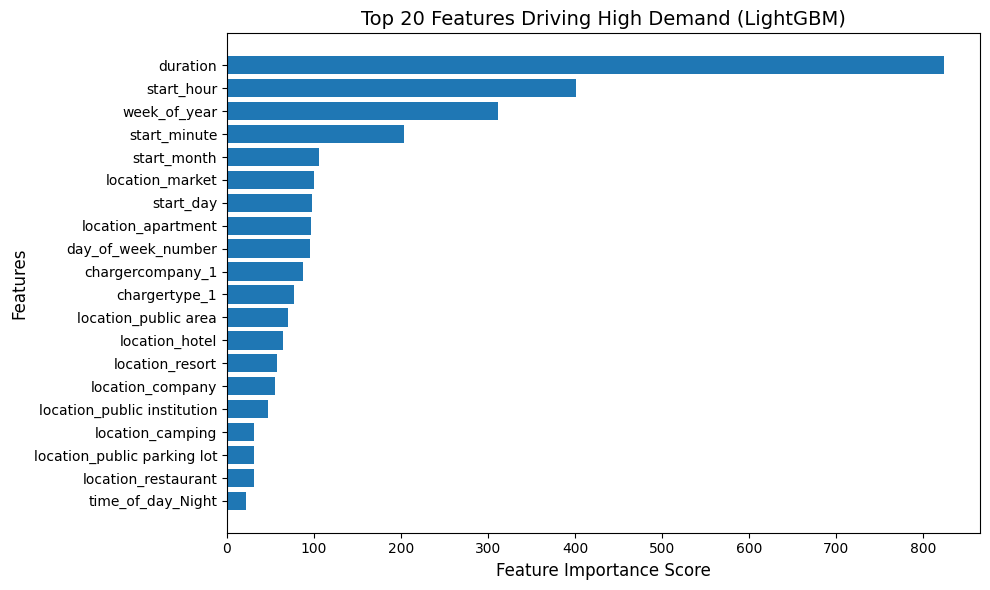

In [89]:
import matplotlib.pyplot as plt
import os

# 1. Extract the trained model and preprocessor from the LightGBM pipeline
best_model = lgb_pipeline.named_steps['classifier']
preprocessor_step = lgb_pipeline.named_steps['preprocessor']

# 2. Get the feature names
# Numeric feature names remain unchanged
num_cols = numeric_features

# Get the categorical feature names created by OneHotEncoder
ohe_step = preprocessor_step.named_transformers_['cat']
cat_cols = ohe_step.get_feature_names_out(categorical_features)

# Combine numeric and encoded categorical feature names in model input order
all_feature_names = num_cols + list(cat_cols)

# 3. Extract feature importances from LightGBM
importances = best_model.feature_importances_

# 4. Create a DataFrame for sorting and viewing
importance_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
})

# Sort from highest to lowest importance
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

# Print the top 20 factors
print("=== Top 20 Factors Driving High Demand ===")
print(importance_df.head(20))

# 5. Plot feature importances
plt.figure(figsize=(10, 6))

# Reverse the top 20 so the most important feature appears at the top
plt.barh(
    importance_df['Feature'].head(20)[::-1],
    importance_df['Importance'].head(20)[::-1],
    color='#1f77b4'
)

plt.title('Top 20 Features Driving High Demand (LightGBM)', fontsize=14)
plt.xlabel('Feature Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.savefig(
    "images/classification_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


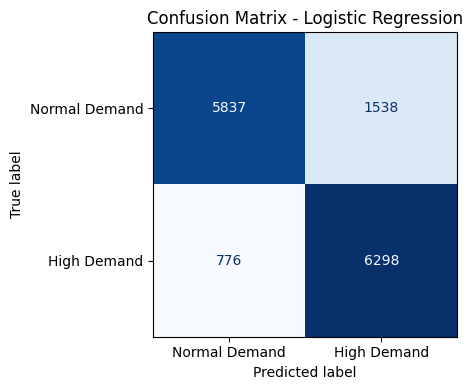

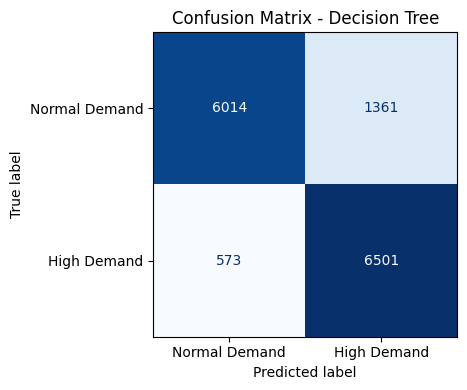

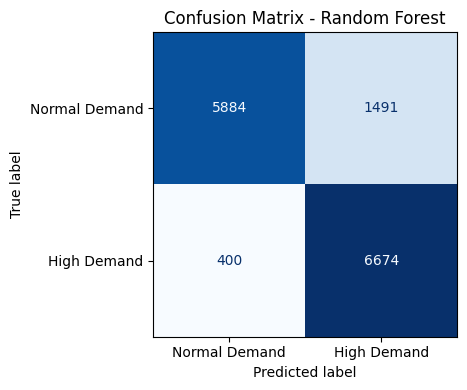

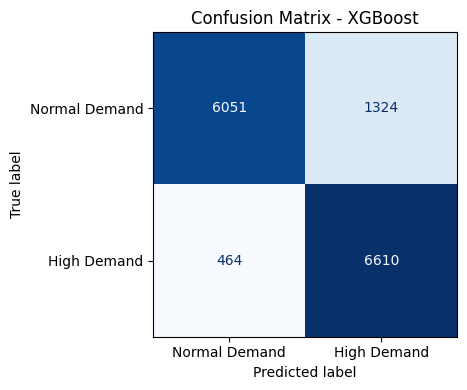

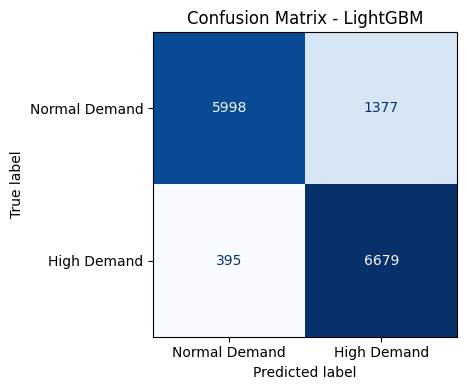

In [90]:
# Confusion Matrix for all Classification Models

import os
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Create images folder
os.makedirs("images", exist_ok=True)

# Store model predictions
model_predictions = {
    "Logistic Regression": y_pred_lr,
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "XGBoost": y_pred_xgb,
    "LightGBM": y_pred_lgb
}

# Create confusion matrix for every model
for model_name, y_pred in model_predictions.items():

    # Calculate confusion matrix
    cm = confusion_matrix(y_test,y_pred)

    # Create figure
    fig, ax = plt.subplots(figsize=(5, 4))

    # Display confusion matrix
    display = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Normal Demand","High Demand"])

    display.plot(ax=ax,cmap="Blues",values_format="d",colorbar=False)

    ax.set_title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    
    # Create safe file name
    file_name = (model_name.lower().replace(" ", "_"))

    # Save image
    plt.savefig(f"images/confusion_matrix_{file_name}.png",dpi=300,bbox_inches="tight")

    plt.show()

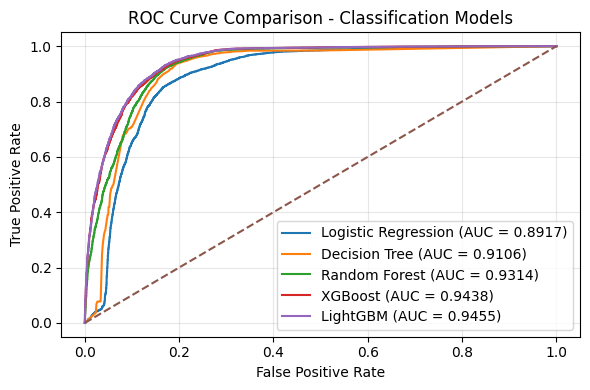

In [91]:
# ROC Curve Comparison

from sklearn.metrics import roc_curve, auc

# Store predicted probabilities
model_probabilities = {
    "Logistic Regression": y_proba_lr,
    "Decision Tree": y_proba_dt,
    "Random Forest": y_proba_rf,
    "XGBoost": y_proba_xgb,
    "LightGBM": y_proba_lgb
}

plt.figure(figsize=(6, 4))

for model_name, y_proba in model_probabilities.items():

    # Calculate False Positive Rate
    # and True Positive Rate
    fpr, tpr, thresholds = roc_curve(
        y_test,
        y_proba
    )

    # Calculate AUC
    roc_auc = auc(
        fpr,
        tpr
    )

    # Plot ROC curve
    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {roc_auc:.4f})"
    )


# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)


plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title(
    "ROC Curve Comparison - Classification Models"
)

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()


# Save graph
plt.savefig(
    "images/classification_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 16. Final model comparison

| Model | Accuracy | Precision | Recall | F1 Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.8429 | 0.8283 | 0.8567 | 0.8423 | 0.8920 |
| Decision Tree | 0.8604 | 0.8346 | 0.8916 | 0.8621 | 0.8958 |
| Random Forest | 0.8776 | 0.8339 | **0.9364** | 0.8822 | 0.9406 |
| XGBoost | **0.8873** | **0.8544** | 0.9278 | 0.8896 | 0.9498 |
| LightGBM | 0.8872 | 0.8519 | 0.9316 | **0.8899** | **0.9501** |


- **Highest Accuracy:** XGBoost — 0.8873
- **Highest Precision:** XGBoost — 0.8544
- **Highest Recall:** Random Forest — 0.9364
- **Highest F1:** LightGBM — 0.8899
- **Highest ROC-AUC:** LightGBM — 0.9501

### Overall interpretation
**XGBoost and LightGBM are the strongest overall models in this notebook.** Their results are extremely close.

Based on overall performance across Accuracy, Precision, Recall, F1 Score, and ROC-AUC, LightGBM was selected as the final classification model because it provides the strongest balance between identifying High Demand sessions and minimizing classification errors.

XGBoost is also a valid final choice if the main priority is the highest Accuracy and Precision.

In [92]:
import pickle

with open("models/lightgbm_classification.pkl", "wb") as file:
    pickle.dump(lgb_pipeline, file)

In [93]:
with open("models/lightgbm_classification.pkl", "rb") as file:
    classification_model = pickle.load(file)

In [94]:
print(type(classification_model))

<class 'sklearn.pipeline.Pipeline'>
